# Atmospheric-DA impact on the land state

Land is not assimilated in these experiments, so any difference between a DART run and the no-DA control at the end of the S0 window comes from the atmospheric forcing (precipitation, radiation, temperature, wind) the land saw during the assimilation month.

The figure compares top-5 cm soil moisture at 1 Jan 2012 00Z (the land initial condition for the January forecasts) in DART10/20/40 with CTRL10:

* **(a)** ensemble-spread ratio DART10 / CTRL10: does DA make the members' land states consistent?
* **(b)** ensemble-mean shift DART10 − CTRL10: where and how much does DA change the land state?
* **(c)** zonal-mean spread for every experiment;
* **(d)** land-mean change in spread and in RMSE against ESA CCI (on cells observed for every experiment).

DART10–CTRL10 has the same ensemble size and is the clean atmospheric-DA attribution; DART20/40 add ensemble-size sensitivity. S1 has no control during the DA window, so this figure is S0 only.

Input: the processed snapshot from `analysis_lnd_init/02_soil_moisture_distribution.ipynb` (run it first).

## 1. Settings

In [1]:
from pathlib import Path

WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
# Must match the PLOT_CONFIG used in analysis_lnd_init/02_soil_moisture_distribution.ipynb.
PROCESSED_FILE = "sm_processed_ESA_CCI_20120101_top05cm_mass_land_alpha0p05.nc"

BASELINE = "CTRL10-S0"
COMPARISONS = ("DART10-S0", "DART20-S0", "DART40-S0")
PRIMARY_EXPERIMENT = "DART10-S0"   # shown in the maps: same size as the control
COLORS = {"CTRL10-S0": "black", "DART10-S0": "#e69f00", "DART20-S0": "#009e73", "DART40-S0": "#d55e00"}
fontsize = 14
FIGURE_DPI = 200
show = True

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
import xarray as xr
import matplotlib.pyplot as plt
from configs.output_paths import workflow_output_dirs
from util.initial_lnd_da_impact import derive_land_da_impact, plot_land_da_impact, save_impact_products

# Input: processed snapshot written by analysis_lnd_init/02_soil_moisture_distribution.ipynb.
init_data_dir, _ = workflow_output_dirs("analysis_lnd_init", output_root=DIAGNOSTIC_OUTPUT_ROOT)
data_dir, figure_dir = workflow_output_dirs("analysis_lnd_model_evaluation", output_root=DIAGNOSTIC_OUTPUT_ROOT)
processed_path = init_data_dir / "processed" / PROCESSED_FILE
if not processed_path.is_file():
    raise FileNotFoundError(f"{processed_path} not found; run analysis_lnd_init/02_soil_moisture_distribution.ipynb first.")
processed = xr.load_dataset(processed_path, engine="scipy")
output_data_dir = data_dir / "atm_da_land_state_impact"
output_figure_dir = figure_dir / "atm_da_land_state_impact"

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 3. Derive and save the impact diagnostics

In [3]:
impact = derive_land_da_impact(processed, baseline=BASELINE, experiments=COMPARISONS)
stem = f"S0_H2OSOI_top{processed.attrs['depth_cm']:02d}cm_{processed.attrs['target_date'].replace('-', '')}_atm_da_land_impact"
summary = save_impact_products(impact, data_path=output_data_dir / f"{stem}.nc", csv_path=output_data_dir / f"{stem}.csv")
print(f"{impact.attrs['n_common_cells']} land cells observed by {impact.attrs['observation']} for every experiment")
summary.round(3)

4590 land cells observed by ESA_CCI for every experiment


sh: getfattr: command not found


,experiment,baseline,land_spread,baseline_land_spread,spread_change_pct,rmse,baseline_rmse,rmse_change_pct,improved_fraction_pct,mean_abs_shift
0,DART10-S0,CTRL10-S0,0.219,0.848,-74.122,2.579,2.511,2.705,47.286,0.749
1,DART20-S0,CTRL10-S0,0.227,0.848,-73.285,2.565,2.511,2.154,46.443,0.761
2,DART40-S0,CTRL10-S0,0.239,0.848,-71.829,2.546,2.511,1.359,47.536,0.754


## 4. Plot

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/analysis_lnd_model_evaluation/atm_da_land_state_impact/S0_H2OSOI_top05cm_20120101_atm_da_land_impact.pdf


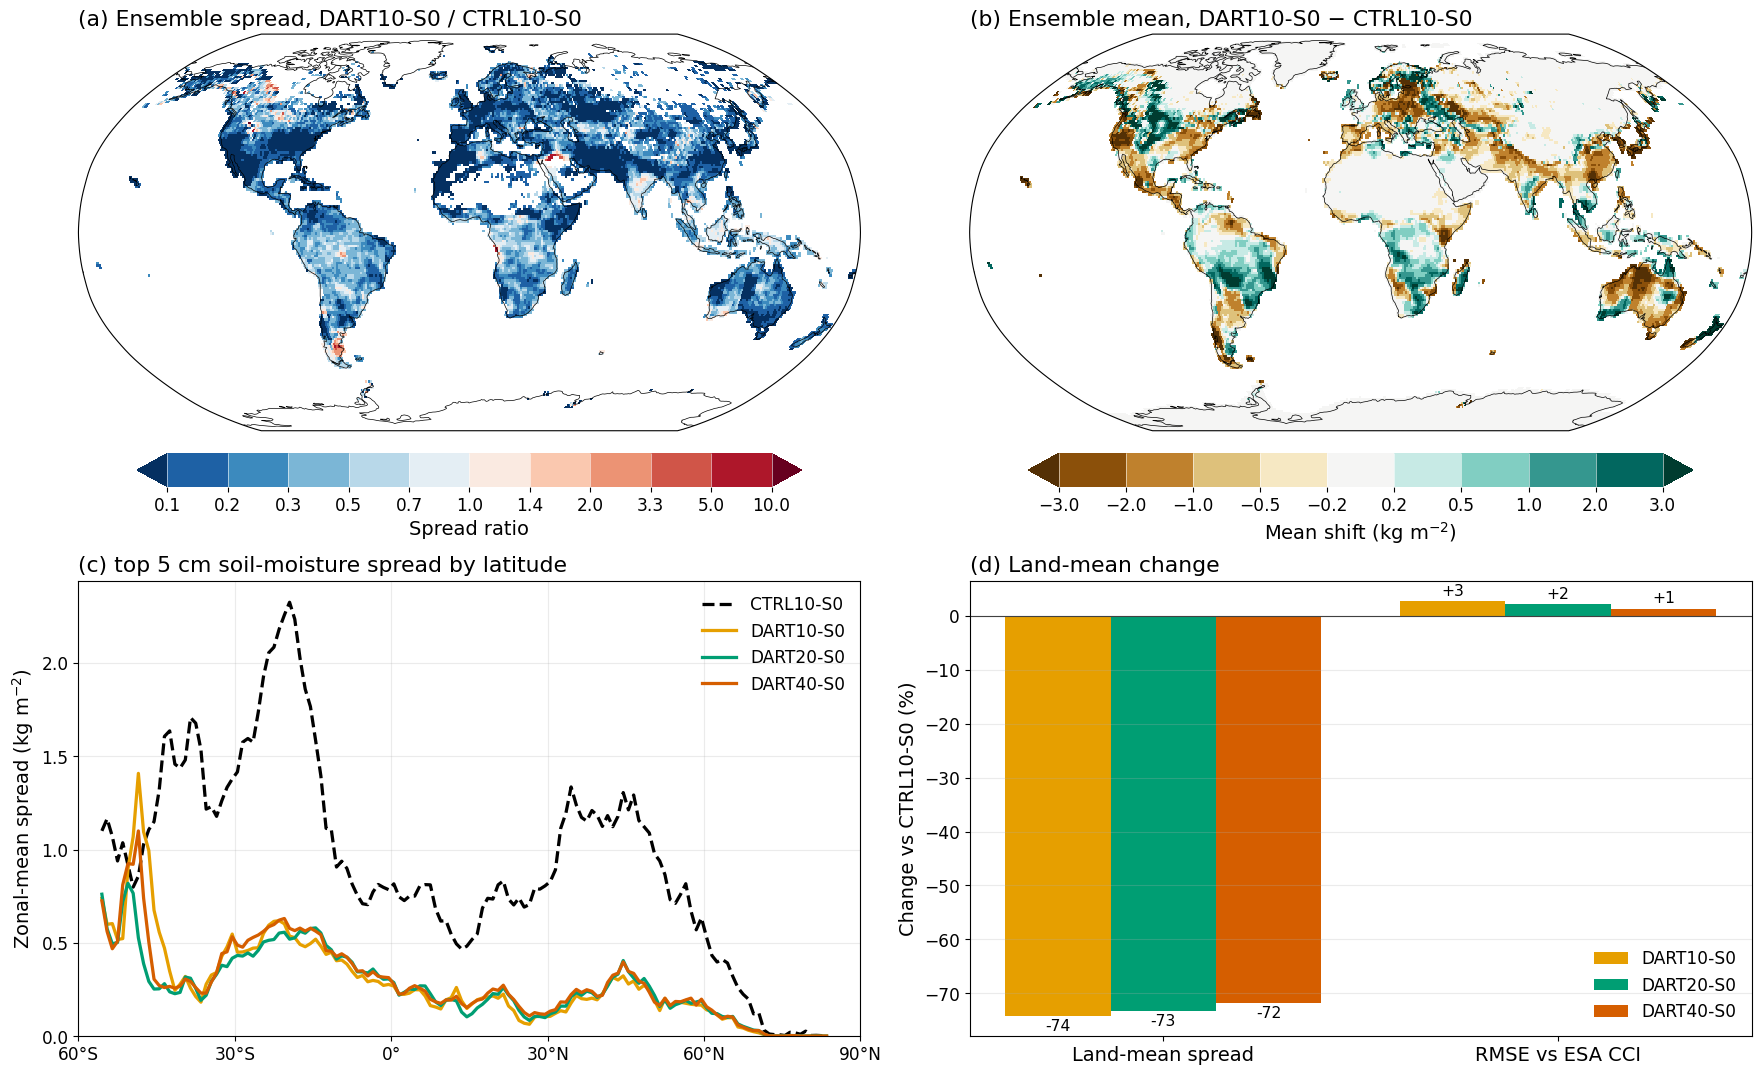

In [4]:
fig = plot_land_da_impact(impact, primary_experiment=PRIMARY_EXPERIMENT, colors=COLORS, fontsize=fontsize)
output_figure_dir.mkdir(parents=True, exist_ok=True)
output = output_figure_dir / f"{stem}.pdf"
fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")  # dpi only affects the rasterized maps
print(f"[FIGURE] {output}")
if not show:
    plt.close(fig)